# LBM D1Q3 quantique : block-encoding de la collision $C$ et circuit du streaming $S$

**Objectif.** Passer du schéma LBM classique
$$F^{n+1} = S\,C\,F^n$$
(cf. `LBM_D1Q3_tableau.typ`) à un **circuit quantique**.

| Opérateur | Unitaire ? | Ce qu'on fait |
|---|---|---|
| $C$ (collision) | **non** | on la **block-encode** avec FABLE (méthode de `block_encoding.ipynb`) |
| $S$ (streaming) | **oui** (permutation) | circuit **exact** d'incréments contrôlés : pas besoin de FABLE |

Plan :
1. matrices classiques $C$, $S$ (notations du tableau, ordre des directions $(0,-,+)$) ;
2. passage à une taille $2^n$ : on ajoute une 4ᵉ direction vide ($3N \to 4N$), ce qui modifie $C$ **et** $S$ ;
3. block-encoding de $C$ avec FABLE → matrice block-encodée + circuit ;
4. version optimisée : $C = C_{loc}\otimes I_N$, on ne block-encode que $C_{loc}$ ($4\times4$) ;
5. circuit de $S$ ;
6. un pas complet $S\,C$ en circuit, puis plusieurs pas simulés et comparés au LBM classique ;
7. bonus : dilatation minimale de $C_{loc}$ (1 seul ancilla).

Requiert `numpy`, `scipy`, `matplotlib`, `qiskit`, `qiskit-aer`, `fable-circuits`.

## 0. Outils repris de `block_encoding.ipynb`

Rappel : $U$ est un block-encoding de $A$ si, en mettant les $m$ ancillas dans $|0^m\rangle$, en
appliquant $U$ puis en projetant les ancillas sur $|0^m\rangle$, on obtient $A$ (à un facteur près) :
$$U = \begin{bmatrix} A/(\alpha N_A) & \cdot \\ \cdot & \cdot \end{bmatrix},
\qquad A = \alpha\,N_A\,\big(\langle 0^m|\otimes I\big)\,U\,\big(|0^m\rangle\otimes I\big).$$

Pour FABLE, `circ, alpha = fable(A, eps)` renvoie un circuit à $2n+1$ qubits ($A$ de taille
$N_A = 2^n$) et le facteur `alpha`. Le bloc en haut à gauche de $U$ vaut $A/(\alpha N_A)$.
Les fonctions ci-dessous sont reprises telles quelles du notebook.

In [21]:
import numpy as np
import scipy.linalg as sl
import matplotlib.pyplot as plt
from fable import fable
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator, Statevector
from qiskit.circuit.library import UnitaryGate
from qiskit_aer import Aer

simulator = Aer.get_backend("unitary_simulator")

def block_encoding(A, eps=1e-6):
    # FABLE block-encoding of A, returned with a check of the relation.
    # Returns (circuit, alpha, unitary, relative_error).
    N = A.shape[0]
    circ, alpha = fable(A, eps)
    U = simulator.run(circ).result().get_unitary(circ)
    # leading N x N block should be A / (alpha * N)
    block = U.data[:N, :N]
    err = np.linalg.norm(alpha * N * block - A) / np.linalg.norm(A)
    return circ, alpha, U, err

def circuit_stats(circ):
    ops = circ.count_ops()
    return circ.num_qubits, circ.depth(), sum(ops.values())

print("setup ok")

setup ok


## 1. Les matrices classiques (notations du tableau)

- directions $a \in \{0,-,+\}$, poids $\omega = (2/3,\ 1/6,\ 1/6)$, vitesse $a\times1 \in \{0,-1,+1\}$ ;
- nœuds $i \in \{0,\dots,N-1\}$ ;
- $F^n = (f^n_0,\ f^n_-,\ f^n_+) \in \mathbb{R}^{3N}$, la composante $(a,i)$ est à la position $a\cdot N + i$.

$$M = (\omega\otimes I_N)(I_N\ I_N\ I_N), \qquad C = \Big(1-\frac1\tau\Big)I_{3N} + \frac{M}{\tau} = C_{loc}\otimes I_N,$$
$$S = \begin{pmatrix} I_N & & \\ & P^- & \\ & & P^+\end{pmatrix}, \qquad (P^+v)_i = v_{i-1},\quad P^- = (P^+)^T.$$

On prend $N = 8$ nœuds ($3$ qubits de position) et $\tau = 0.8$.

In [35]:
tau = 0.8
k = 3                      # nombre de qubits de position
N = 2**k                   # nombre de noeuds
w = np.array([2/3, 1/6, 1/6])          # ordre (0, -, +)
c = np.array([0, -1, +1])              # a x 1

I_N = np.eye(N)
M = np.kron(w[:, None], I_N) @ np.hstack([I_N, I_N, I_N])     # (w (x) I_N)(I_N I_N I_N), 3N x 3N
C = (1 - 1/tau)*np.eye(3*N) + M/tau                            # 3N x 3N

C_loc = (1 - 1/tau)*np.eye(3) + np.outer(w, np.ones(3))/tau    # 3 x 3
print("C = C_loc (x) I_N :", np.allclose(C, np.kron(C_loc, I_N)))

P_plus = np.roll(I_N, 1, axis=0)        # (P+ v)_i = v_{i-1}
P_minus = P_plus.T
Z = np.zeros((N, N))
S = np.block([[I_N, Z, Z],
              [Z, P_minus, Z],
              [Z, Z, P_plus]])          # 3N x 3N
print("P+ @ (0,1,...,N-1) =", P_plus @ np.arange(N))
print("S unitaire :", np.allclose(S.T @ S, np.eye(3*N)))
print("C unitaire :", np.allclose(C.T @ C, np.eye(3*N)))
np.set_printoptions(precision=3, suppress=True)
print("C_loc =\n", C_loc)

C = C_loc (x) I_N : True
P+ @ (0,1,...,N-1) = [7. 0. 1. 2. 3. 4. 5. 6.]
S unitaire : True
C unitaire : False
C_loc =
 [[ 0.583  0.833  0.833]
 [ 0.208 -0.042  0.208]
 [ 0.208  0.208 -0.042]]


**Vérification** : $F^{n+1} = S\,C\,F^n$ redonne exactement le LBM « boucle » du notebook `lbm.ipynb`
(collision puis `np.roll`).

In [23]:
def lbm_step_loop(f):
    # f de forme (3, N), ordre (0, -, +) : collision puis streaming
    rho = f.sum(axis=0)
    fs = f - (f - w[:, None]*rho)/tau
    return np.stack([fs[0], np.roll(fs[1], -1), np.roll(fs[2], +1)])

x = np.arange(N)
rho0 = np.exp(-(x - N/2)**2/(2*1.5**2))
f = w[:, None]*rho0                     # initialisation a l'equilibre
F = f.reshape(-1)                       # F^0 in R^{3N}

for _ in range(5):
    f = lbm_step_loop(f)
    F = S @ C @ F
print("max |F_matriciel - F_boucle| =", np.abs(F - f.reshape(-1)).max())

max |F_matriciel - F_boucle| = 1.6653345369377348e-16


## 2. Passage à une taille $2^n$ : $3N \to 4N$

Un registre de $q$ qubits contient $2^q$ amplitudes. $3N$ n'est pas une puissance de 2, on ajoute donc
une **4ᵉ direction fictive** « $\varnothing$ », toujours vide :
$$F^n = (f^n_0,\ f^n_-,\ f^n_+,\ \underbrace{0}_{f_\varnothing}) \in \mathbb{R}^{4N},
\qquad |F^n\rangle = \sum_{a,i} f^n_{a,i}\,|a\rangle_{\text{dir}}\,|i\rangle_{\text{pos}}$$
avec **2 qubits de direction** et $k=\log_2 N$ **qubits de position** ($4N = 2^{k+2}$).

C'est là que **$C$ et $S$ changent de forme** (mais pas de physique) :

$$C_4 = C_{loc,4}\otimes I_N,\quad C_{loc,4} = \begin{pmatrix} C_{loc} & 0 \\ 0 & 0\end{pmatrix}\ (4\times4),
\qquad
S_4 = \begin{pmatrix} I_N &&& \\ & P^- && \\ && P^+ & \\ &&& I_N\end{pmatrix}\ (4N\times4N).$$

- dans $C_4$ la direction $\varnothing$ est mise à 0 (elle ne reçoit rien) ;
- dans $S_4$ on met $I_N$ sur la direction $\varnothing$ pour que $S_4$ **reste unitaire**.

In [24]:
C_loc4 = np.zeros((4, 4)); C_loc4[:3, :3] = C_loc
C4 = np.kron(C_loc4, I_N)                                   # 4N x 4N
S4 = np.block([[I_N, Z, Z, Z],
               [Z, P_minus, Z, Z],
               [Z, Z, P_plus, Z],
               [Z, Z, Z, I_N]])                             # 4N x 4N
D = 4*N
print("taille :", C4.shape, "=", f"2^{int(np.log2(D))}")
print("S4 unitaire :", np.allclose(S4.T @ S4, np.eye(D)))
print("le bloc 3N x 3N de S4 C4 est S C :", np.allclose((S4 @ C4)[:3*N, :3*N], S @ C))

taille : (64, 64) = 2^6
S4 unitaire : True
le bloc 3N x 3N de S4 C4 est S C : True


**Convention Qiskit** (little-endian) : l'indice $a\cdot N + i$ d'un vecteur de $2^{k+2}$ amplitudes
s'écrit en binaire avec les bits de poids faible = position $i$ et les 2 bits de poids fort = direction $a$.
Donc **qubits $0,\dots,k-1$ = position** et **qubits $k, k+1$ = direction**, codée
$0 \to |00\rangle$, $- \to |01\rangle$, $+ \to |10\rangle$, $\varnothing \to |11\rangle$
(notation $|q_{k+1}q_k\rangle$).

## 3. Block-encoding de $C$ avec FABLE (matrice complète $4N\times4N$)

On applique directement la méthode de `block_encoding.ipynb` à $C_4$.

In [25]:
circ_C, alpha_C, U_C, err_C = block_encoding(C4)
nq, depth, gates = circuit_stats(circ_C)
print(f"C4 : {D}x{D}  ({k+2} qubits systeme)")
print(f"circuit : {nq} qubits ({k+2} systeme + {nq-(k+2)} ancillas), profondeur {depth}, {gates} portes")
print(f"alpha = {alpha_C:.4f}")
print(f"facteur total alpha * D = {alpha_C*D:.1f}   ->   bloc haut-gauche de U = C4 / {alpha_C*D:.0f}")
print(f"erreur relative du block-encoding = {err_C:.3e}")

C4 : 64x64  (6 qubits systeme)
circuit : 13 qubits (6 systeme + 7 ancillas), profondeur 574, 590 portes
alpha = 1.0000
facteur total alpha * D = 64.0   ->   bloc haut-gauche de U = C4 / 64
erreur relative du block-encoding = 4.456e-15


**La matrice block-encodée** : $U$ est un unitaire $2^{2(k+2)+1}\times 2^{2(k+2)+1}$. Son bloc
haut-gauche $D\times D$ (ancillas dans $|0\rangle$) est $C_4/(\alpha D)$ :

U unitaire : True
taille de U : (8192, 8192)


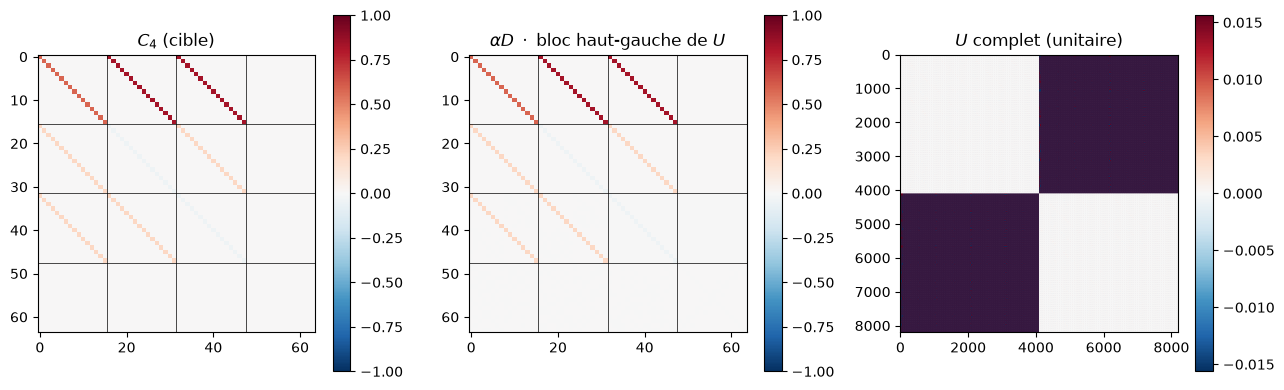

In [26]:
block_C = U_C.data[:D, :D]
print("U unitaire :", np.allclose(U_C.data.conj().T @ U_C.data, np.eye(U_C.data.shape[0])))
print("taille de U :", U_C.data.shape)

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
im = ax[0].imshow(C4, cmap='RdBu_r', vmin=-1, vmax=1); ax[0].set_title(r'$C_4$ (cible)')
plt.colorbar(im, ax=ax[0])
im = ax[1].imshow(np.real(alpha_C*D*block_C), cmap='RdBu_r', vmin=-1, vmax=1)
ax[1].set_title(r'$\alpha D\ \cdot$ bloc haut-gauche de $U$'); plt.colorbar(im, ax=ax[1])
im = ax[2].imshow(np.real(U_C.data), cmap='RdBu_r'); ax[2].set_title(r'$U$ complet (unitaire)')
plt.colorbar(im, ax=ax[2])
for a in ax[:2]:
    for t in (N, 2*N, 3*N):
        a.axhline(t-0.5, color='k', lw=0.5); a.axvline(t-0.5, color='k', lw=0.5)
plt.tight_layout(); plt.show()

Le circuit FABLE (rotations $R_y$ + CNOT) est long : on affiche sa composition et ses 20 premières portes.

In [27]:
print("portes :", dict(circ_C.count_ops()))
debut = QuantumCircuit(circ_C.num_qubits)
for inst in circ_C.data[:20]:
    debut.append(inst)
print("20 premieres portes :")
print(debut.draw(output='text', fold=120))

portes : {'cx': 316, 'ry': 256, 'h': 12, 'swap': 6}
20 premieres portes :
      ┌────────────┐┌───┐┌────────────────┐┌───┐┌───────────────┐┌───┐┌────────────────┐┌───┐┌───┐┌────────────────┐»
 q_0: ┤ Ry(3.1154) ├┤ X ├┤ Ry(-0.0081451) ├┤ X ├┤ Ry(0.0098753) ├┤ X ├┤ Ry(-0.0081451) ├┤ X ├┤ X ├┤ Ry(-0.0081451) ├»
      └───┬───┬────┘└─┬─┘└────────────────┘└─┬─┘└───────────────┘└─┬─┘└────────────────┘└─┬─┘└─┬─┘└────────────────┘»
 q_1: ────┤ H ├───────┼──────────────────────┼─────────────────────┼──────────────────────┼────┼────────────────────»
          ├───┤       │                      │                     │                      │    │                    »
 q_2: ────┤ H ├───────┼──────────────────────┼─────────────────────┼──────────────────────┼────┼────────────────────»
          ├───┤       │                      │                     │                      │    │                    »
 q_3: ────┤ H ├───────┼──────────────────────┼─────────────────────┼──────────────────────┼────┼────

## 4. Mieux : block-encoder seulement $C_{loc}$ ($4\times4$)

Comme $C_4 = C_{loc,4}\otimes I_N$, la collision **n'agit que sur les 2 qubits de direction** et laisse
les qubits de position intacts. Il suffit donc de block-encoder $C_{loc,4}$ et d'appliquer ce petit
circuit sur les qubits de direction :

$$U_{C_4} = U_{C_{loc}} \otimes I_N \quad\Rightarrow\quad
\text{bloc haut-gauche} = \frac{C_{loc,4}}{4\alpha}\otimes I_N = \frac{C_4}{4\alpha}.$$

Avantages : circuit **indépendant de $N$**, et facteur de normalisation $4\alpha$ au lieu de $4N\alpha$.

In [28]:
circ_loc, alpha_loc, U_loc, err_loc = block_encoding(C_loc4)
nq, depth, gates = circuit_stats(circ_loc)
print(f"C_loc4 : 4x4 (2 qubits)")
print(f"circuit : {nq} qubits (2 systeme + {nq-2} ancillas), profondeur {depth}, {gates} portes")
print(f"alpha = {alpha_loc:.4f}, facteur total = {alpha_loc*4:.1f}")
print(f"erreur relative = {err_loc:.3e}")
print("bloc 4x4 * 4 alpha =\n", np.real(alpha_loc*4*U_loc.data[:4, :4]))
print("\ncomparaison avec FABLE sur C4 complet :")
print(f"  portes     : {circuit_stats(circ_C)[2]}  ->  {gates}")
print(f"  facteur    : {alpha_C*D:.0f}  ->  {alpha_loc*4:.0f}")

C_loc4 : 4x4 (2 qubits)
circuit : 5 qubits (2 systeme + 3 ancillas), profondeur 34, 38 portes
alpha = 1.0000, facteur total = 4.0
erreur relative = 3.453e-16
bloc 4x4 * 4 alpha =
 [[ 0.583  0.833  0.833 -0.   ]
 [ 0.208 -0.042  0.208  0.   ]
 [ 0.208  0.208 -0.042 -0.   ]
 [ 0.    -0.    -0.     0.   ]]

comparaison avec FABLE sur C4 complet :
  portes     : 590  ->  38
  facteur    : 64  ->  4


In [29]:
print(circ_loc.draw(output='text', fold=120))

                                                                                                         »
q_0: ────────────────■──────────────────────────────────────■─────────────────────────────────────────■──»
                     │                                      │                                         │  »
q_1: ────────────────┼────────────────────■─────────────────┼─────────────────────────────────────────┼──»
         ┌───┐       │                    │                 │                                         │  »
q_2: ────┤ H ├───────┼────────────────────┼─────────────────┼────────────────────■────────────────────┼──»
         ├───┤       │                    │                 │                    │                    │  »
q_3: ────┤ H ├───────┼────────────────────┼─────────────────┼────────────────────┼────────────────────┼──»
     ┌───┴───┴────┐┌─┴─┐┌──────────────┐┌─┴─┐┌───────────┐┌─┴─┐┌──────────────┐┌─┴─┐┌──────────────┐┌─┴─┐»
q_4: ┤ Ry(2.7229) ├┤ X ├┤ Ry(-0.13032

Dans ce circuit, `q_0, q_1` sont les qubits système (ici : la direction) et `q_2, q_3, q_4` les ancillas.

## 5. Circuit du streaming $S_4$

$S_4$ est une **permutation**, donc déjà unitaire : on n'a **pas besoin** de la block-encoder.
On la construit exactement :

- direction $-$ (état $|01\rangle$) : $i \to i-1$ sur les qubits de position = **décrément** $P^-$ ;
- direction $+$ (état $|10\rangle$) : $i \to i+1$ = **incrément** $P^+$ ;
- directions $0$ et $\varnothing$ : rien.

L'incrément modulo $2^k$ se fait avec une cascade de portes multi-contrôlées (le bit $j$ bascule si
tous les bits de poids plus faible valent 1). Le décrément est son inverse.

In [30]:
def increment(m):
    # |i> -> |i+1 mod 2^m>  (= P+)
    qc = QuantumCircuit(m, name="+1")
    for j in reversed(range(m)):
        if j == 0:
            qc.x(0)
        else:
            qc.mcx(list(range(j)), j)
    return qc

inc = increment(k)
print("increment = P+ :", np.allclose(Operator(inc).data, P_plus))

pos = list(range(k)); dirq = [k, k+1]
circ_S = QuantumCircuit(k+2, name="S")
# ctrl_state s'ecrit |q_{k+1} q_k> : '01' = direction '-', '10' = direction '+'
circ_S.append(inc.inverse().to_gate(label="P-").control(2, ctrl_state='01'), dirq + pos)
circ_S.append(inc.to_gate(label="P+").control(2, ctrl_state='10'), dirq + pos)
print("circuit = S4 :", np.allclose(Operator(circ_S).data, S4))
print(circ_S.draw(output='text'))

increment = P+ : True
circuit = S4 : True
     ┌─────┐┌─────┐
q_0: ┤0    ├┤0    ├
     │     ││     │
q_1: ┤1    ├┤1    ├
     │  P- ││  P+ │
q_2: ┤2    ├┤2    ├
     │     ││     │
q_3: ┤3    ├┤3    ├
     └──┬──┘└──┬──┘
q_4: ───■──────o───
        │      │   
q_5: ───o──────■───
                   


**Pourquoi pas FABLE pour $S$ ?** FABLE marche sur n'importe quelle matrice, mais il la
*sous-normalise* : le bloc vaut $S_4/(\alpha D)$. On ne récupèrerait $S_4$ qu'avec une probabilité
$\sim 1/(\alpha D)^2$, alors que le circuit exact l'applique avec probabilité 1.

In [31]:
circ_S_fable, alpha_S, U_S, err_S = block_encoding(S4)
print(f"FABLE sur S4 : {circuit_stats(circ_S_fable)[2]} portes, facteur {alpha_S*D:.0f} "
      f"-> probabilite de succes ~ 1/{(alpha_S*D)**2:.0f}")
t = transpile(circ_S, basis_gates=['cx', 'u'], optimization_level=1)
print(f"circuit exact   : {sum(t.count_ops().values())} portes (cx+u), facteur 1 -> probabilite 1")

FABLE sur S4 : 2080 portes, facteur 64 -> probabilite de succes ~ 1/4096
circuit exact   : 1838 portes (cx+u), facteur 1 -> probabilite 1


## 6. Un pas complet $F^{n+1} = S_4\,C_4\,F^n$ en circuit

On enchaîne le block-encoding de la collision (sur les qubits de direction + 3 ancillas) puis $S_4$
(sur direction + position). Les ancillas sont les qubits de poids fort : le bloc haut-gauche
$D\times D$ du circuit total vaut
$$\frac{S_4\,C_4}{4\alpha}.$$

In [32]:
n_anc = circ_loc.num_qubits - 2
anc = list(range(k+2, k+2+n_anc))

step = QuantumCircuit(k+2+n_anc, name="pas LBM")
step.compose(circ_loc, qubits=dirq + anc, inplace=True)      # collision (block-encodee)
step.barrier()
step.compose(circ_S, qubits=pos + dirq, inplace=True)        # streaming (exact)

scale = 4*alpha_loc
U_step = Operator(step).data
print(f"qubits : {k} position + 2 direction + {n_anc} ancillas = {step.num_qubits}")
print("bloc haut-gauche * 4 alpha = S4 C4 :", np.allclose(scale*U_step[:D, :D], S4 @ C4))
print(step.draw(output='text', fold=120))

qubits : 4 position + 2 direction + 3 ancillas = 9
bloc haut-gauche * 4 alpha = S4 C4 : True
                                                                                                         »
q_0: ────────────────────────────────────────────────────────────────────────────────────────────────────»
                                                                                                         »
q_1: ────────────────────────────────────────────────────────────────────────────────────────────────────»
                                                                                                         »
q_2: ────────────────────────────────────────────────────────────────────────────────────────────────────»
                                                                                                         »
q_3: ────────────────────────────────────────────────────────────────────────────────────────────────────»
                                                   

## 7. Plusieurs pas : simulation et post-sélection

À chaque pas : on prépare $|0\rangle_{anc}|F^n\rangle$, on applique le circuit, et on **garde** le
résultat seulement si les ancillas sont mesurés dans $|0\rangle$ (post-sélection). L'état obtenu est
$\propto S_4 C_4 F^n$. On garde la norme classiquement pour reconstituer $F^n$, puis $\rho^n_i = \sum_a f^n_{a,i}$.

On compare au LBM classique et on regarde la **probabilité de succès** de chaque pas.

In [36]:
def run_quantum(rho0, steps, step_circ, scale):
    F = np.concatenate([w[0]*rho0, w[1]*rho0, w[2]*rho0, np.zeros(N)])   # F^0 in R^{4N}
    norm = np.linalg.norm(F); psi = F/norm
    probs = []
    for _ in range(steps):
        full = np.zeros(2**step_circ.num_qubits, dtype=complex)
        full[:D] = psi                                     # ancillas dans |0>
        out = Statevector(full).evolve(step_circ).data[:D] # post-selection ancillas = |0>
        p = np.linalg.norm(out)**2
        probs.append(p)
        norm *= np.sqrt(p)*scale
        psi = out/np.sqrt(p)
    F = np.real(norm*psi)
    return F[:N] + F[N:2*N] + F[2*N:3*N], np.array(probs)

steps = 10
rho_q, probs = run_quantum(rho0, steps, step, scale)

f = w[:, None]*rho0
for _ in range(steps):
    f = lbm_step_loop(f)
rho_c = f.sum(axis=0)

print(f"max |rho_quantique - rho_classique| = {np.abs(rho_q - rho_c).max():.2e}")
print("probabilite de succes par pas :", np.round(probs, 4))
print(f"probabilite de succes cumulee sur {steps} pas : {np.prod(probs):.2e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(x, rho0, 'k:', label='t=0')
ax[0].plot(x, rho_c, 'b-', lw=2, label='LBM classique')
ax[0].plot(x, rho_q, 'ro', label='circuit quantique')
ax[0].set_xlabel('noeud i'); ax[0].set_ylabel(r'$\rho_i$'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[0].set_title(f'{steps} pas, N={N}, tau={tau}')
ax[1].semilogy(np.arange(1, steps+1), np.cumprod(probs), 'o-')
ax[1].set_xlabel('pas'); ax[1].set_ylabel('proba cumulee'); ax[1].grid(alpha=0.3)
ax[1].set_title('cout de la post-selection')
plt.tight_layout(); plt.show()

ValueError: could not broadcast input array from shape (56,) into shape (64,)

**Le résultat est exact**, mais chaque pas ne réussit qu'avec une probabilité $\approx 6\%$ (le facteur
$4\alpha = 4$ divise les amplitudes) : sur $T$ pas, la probabilité décroît comme $0.06^T$. C'est la limite
principale de l'approche « un block-encoding par pas ». Le facteur minimal possible est
$\sigma_{\max}(C_{loc})$, ce que donne la dilatation ci-dessous.

## 8. Bonus : dilatation minimale (1 seul ancilla)

Avec $A = C_{loc,4}/\sigma_{\max}$ (donc $\|A\|\le1$), la matrice
$$U_{C} = \begin{pmatrix} A & \sqrt{I-AA^T} \\ \sqrt{I-A^TA} & -A^T \end{pmatrix}$$
est unitaire ($8\times8$, 3 qubits) et contient $A$ en haut à gauche. Facteur : $\sigma_{\max}\approx1.35$
au lieu de $4$.

In [34]:
sigma = np.linalg.svd(C_loc4, compute_uv=False)[0]
A = C_loc4/sigma
U_dil = np.block([[A, np.real(sl.sqrtm(np.eye(4) - A @ A.T))],
                  [np.real(sl.sqrtm(np.eye(4) - A.T @ A)), -A.T]])
print(f"sigma_max(C_loc) = {sigma:.4f}")
print("U_C unitaire :", np.allclose(U_dil @ U_dil.T, np.eye(8)))

circ_dil = QuantumCircuit(3, name="U_C")
circ_dil.append(UnitaryGate(U_dil, label="U_C"), [0, 1, 2])   # q0,q1 = direction, q2 = ancilla
t = transpile(circ_dil, basis_gates=['cx', 'u'], optimization_level=1)
print("portes apres transpilation :", dict(t.count_ops()))

step_dil = QuantumCircuit(k+3, name="pas LBM (dilatation)")
step_dil.compose(circ_dil, qubits=dirq + [k+2], inplace=True)
step_dil.compose(circ_S, qubits=pos + dirq, inplace=True)
print("bloc * sigma = S4 C4 :", np.allclose(sigma*Operator(step_dil).data[:D, :D], S4 @ C4))

rho_d, probs_d = run_quantum(rho0, steps, step_dil, sigma)
print(f"max |rho - rho_classique| = {np.abs(rho_d - rho_c).max():.2e}")
print("probabilite par pas :", np.round(probs_d, 3))
print(f"cumulee sur {steps} pas : FABLE {np.prod(probs):.1e}  vs  dilatation {np.prod(probs_d):.1e}")

sigma_max(C_loc) = 1.3451
U_C unitaire : True
portes apres transpilation : {'u': 35, 'cx': 19}
bloc * sigma = S4 C4 : True
max |rho - rho_classique| = 4.90e-14
probabilite par pas : [0.553 0.511 0.538 0.532 0.535 0.536 0.537 0.538 0.539 0.539]
cumulee sur 10 pas : FABLE 6.6e-13  vs  dilatation 1.9e-03


## Bilan

| Élément | Résultat |
|---|---|
| $C$ (non unitaire) | block-encodée par FABLE : bloc haut-gauche de $U$ = $C_4/(\alpha\,4N)$, erreur $\sim10^{-15}$ |
| optimisation | $C = C_{loc}\otimes I_N$ → FABLE sur $C_{loc}$ seul (5 qubits), facteur $4$ indépendant de $N$ |
| $S$ (unitaire) | modifiée seulement par le passage $3N\to4N$ (bloc $I_N$ sur la direction fictive) ; circuit exact d'incréments contrôlés, **sans FABLE** |
| un pas | circuit = $U_{C_{loc}}$ (direction + ancillas) puis $S$ (direction + position), bloc = $S_4C_4/(4\alpha)$ |
| validation | plusieurs pas simulés = LBM classique à $10^{-13}$ près |
| limite | post-sélection à chaque pas : probabilité $\approx p^T$ ; la dilatation minimale améliore $p$ (≈ 6 % → ≈ 55 %) |

**Pistes pour la suite** : amplification d'amplitude pour réduire le coût de la post-sélection,
ou block-encoder directement plusieurs pas $(S C)^T$ / formuler le problème comme un système linéaire.